# Day 94 – Model Evaluation & Error Analysis

## Objective
Evaluate the trained Loan Approval classification models using multiple performance metrics and understand their prediction errors.

## Today's Tasks
- Evaluate all trained models.
- Calculate Accuracy, Precision, Recall, and F1-score.
- Analyze Confusion Matrix.
- Compare model performance.
- Identify the most suitable model based on evaluation results.

In [1]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from google.colab import files

# Upload dataset
uploaded = files.upload()

# Automatically detect uploaded filename
filename = next(iter(uploaded))

# Load dataset
df = pd.read_csv(filename)

# Separate features and target
X = df.drop(columns=["Loan_ID", "Loan_Status"])
y = df["Loan_Status"]

# Identify column types
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Dataset Loaded:", df.shape)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Data preparation completed successfully!")

Saving train_u6lujuX_CVtuZ9i (1).csv to train_u6lujuX_CVtuZ9i (1).csv
Dataset Loaded: (614, 13)
Training Data: (491, 11)
Testing Data: (123, 11)
Data preparation completed successfully!


In [3]:
def create_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return preprocessor

print("Preprocessing function ready!")

Preprocessing function ready!


In [4]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42))
    ]),

    "SVM": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", SVC())
    ])
}

print("All 4 evaluation models are ready!")

All 4 evaluation models are ready!


In [5]:
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
SVM trained successfully!

All models trained successfully!


In [6]:
evaluation_results = []

for name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="Y"),
        "Recall": recall_score(y_test, y_pred, pos_label="Y"),
        "F1 Score": f1_score(y_test, y_pred, pos_label="Y")
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

evaluation_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8618,0.8400,0.9882,0.9081
1,SVM,0.8537,0.8317,0.9882,0.9032
2,Random Forest,0.8211,0.8462,0.9059,0.8750
3,Decision Tree,0.7561,0.8235,0.8235,0.8235


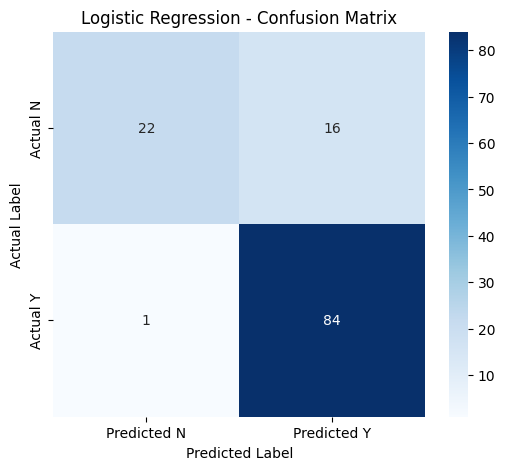

Confusion Matrix:
[[22 16]
 [ 1 84]]


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions from Logistic Regression
y_pred_lr = models["Logistic Regression"].predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=["N", "Y"])

# Visualize
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted N", "Predicted Y"],
    yticklabels=["Actual N", "Actual Y"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

In [8]:
for name, pipeline in models.items():
    y_pred = pipeline.predict(X_test)

    print("=" * 60)
    print(f"MODEL: {name}")
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=["N", "Y"],
        target_names=["Rejected (N)", "Approved (Y)"],
        zero_division=0
    ))

MODEL: Logistic Regression
              precision    recall  f1-score   support

Rejected (N)       0.96      0.58      0.72        38
Approved (Y)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123

MODEL: Decision Tree
              precision    recall  f1-score   support

Rejected (N)       0.61      0.61      0.61        38
Approved (Y)       0.82      0.82      0.82        85

    accuracy                           0.76       123
   macro avg       0.71      0.71      0.71       123
weighted avg       0.76      0.76      0.76       123

MODEL: Random Forest
              precision    recall  f1-score   support

Rejected (N)       0.75      0.63      0.69        38
Approved (Y)       0.85      0.91      0.88        85

    accuracy                           0.82       123
   macro avg       0.80      0.77      0.78       123
weigh

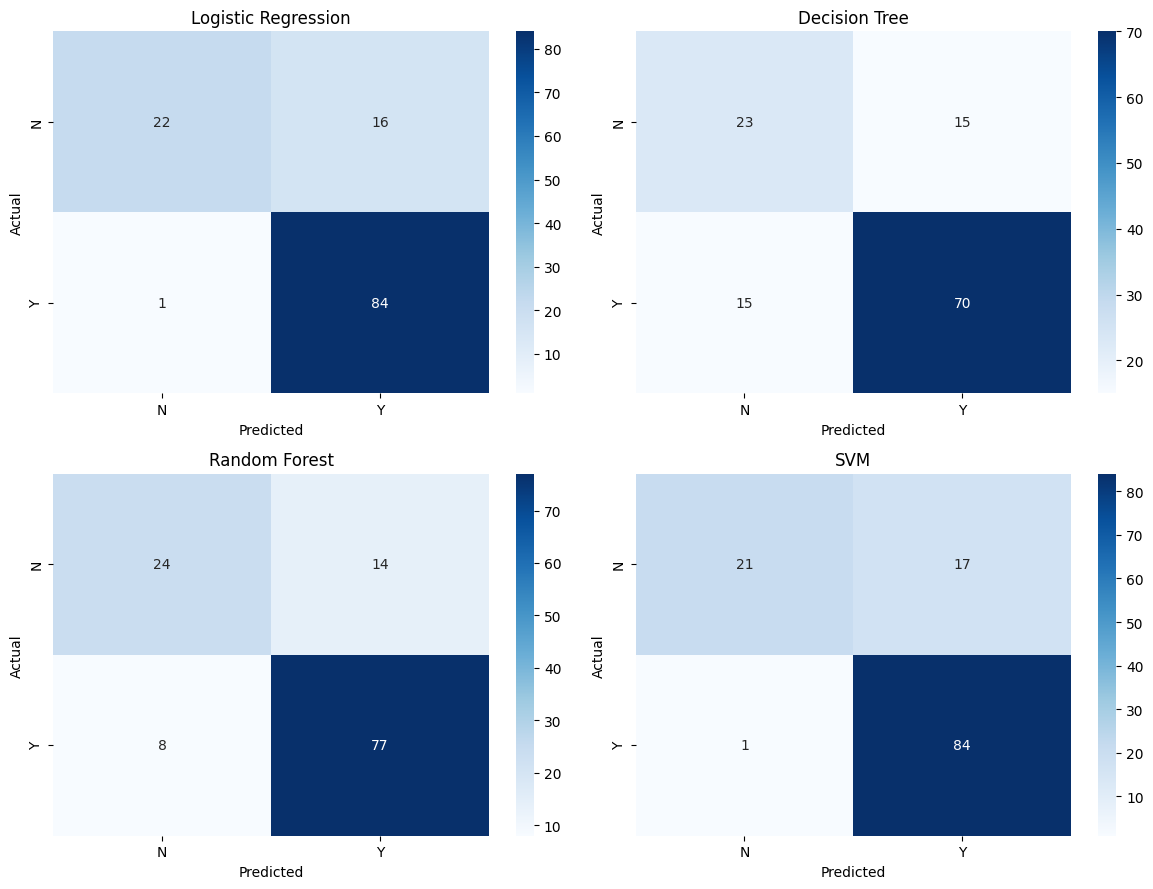

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, pipeline) in zip(axes.flatten(), models.items()):
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=["N", "Y"])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["N", "Y"],
        yticklabels=["N", "Y"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Day 94 – Model Evaluation & Error Analysis Conclusion

##In this session, four machine learning models were evaluated using Accuracy, Precision, Recall, F1-score, Classification Report, and Confusion Matrix. Logistic Regression achieved the highest accuracy of 86.18% and the highest F1-score of 90.81%, making it the best overall model in this comparison. SVM also performed closely, with an accuracy of 85.37%.

##The confusion matrix analysis showed that Logistic Regression correctly predicted 22 rejected applicants and 84 approved applicants, while making 17 incorrect predictions. Random Forest performed better at identifying rejected applicants, correctly classifying 24 out of 38 rejected cases, but it had lower overall accuracy. The analysis also revealed that all models performed better at identifying approved applicants than rejected applicants.

##Based on the overall evaluation, Logistic Regression was selected as the provisional best model. Further improvements may focus on better identifying rejected applicants and reducing false approvals.

#**Day 94 Status: Completed**